In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from scipy.ndimage import gaussian_filter
import os

In [128]:
# My original version. Computes moments well but struggles with fits headers. Replaced by bottom.

def compute_zeroth_moment_galactic(fits_file, catalog_file, output_dir, smoothing_sigma=2.0):
    # Load the FITS file
    with fits.open(fits_file) as hdul:
        data = hdul[0].data
        header = hdul[0].header

    # Apply Gaussian smoothing, noise calculation, and masking as before
    #smoothed_data = gaussian_filter(data, sigma=smoothing_sigma)
    #noise_map = np.median(np.abs(smoothed_data - np.median(smoothed_data)), axis=0)
    #mask = smoothed_data > (3 * noise_map)
    #masked_data = np.where(mask, smoothed_data, np.nan)

    # Parse WCS information
    wcs = WCS(header)

    # Ensure WCS uses Galactic coordinates
    if 'GLON' not in wcs.wcs.ctype[0] or 'GLAT' not in wcs.wcs.ctype[1]:
        raise ValueError("FITS file does not use Galactic coordinates (l, b).")

    # Calculate spatial padding
    spatial_padding = 5 # James asked for 4 arcmin and we have 30 arcsec pixels so that's 4 pixels. Changed it to 5 later.


    # Load the catalog
    catalog_data = pd.read_csv(catalog_file)

    # Ensure the output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # Process each structure in the catalog
    for _, entry in catalog_data.iterrows():
        source_name = entry['HiGAL_id']  # Assuming the column for source names is 'Name'
        l = entry['gal_long']           # Galactic Longitude
        b = entry['gal_lat']           # Galactic Latitude
        v_center = entry['vlsr_2']  # Central velocity
        stddev = entry['dvlsr']      # Standard deviation of velocity

        # Shouldn't these be outside? They are calculated for the cube, not the sources
        
        l_low=header['CRVAL1']+(header['NAXIS1']-header['CRPIX1'])*header['CDELT1']
        l_high=header['CRVAL1']+(1-header['CRPIX1'])*header['CDELT1']

        b_high=header['CRVAL2']+(header['NAXIS2']-header['CRPIX2'])*header['CDELT2']
        b_low=header['CRVAL2']+(1-header['CRPIX2'])*header['CDELT2']

        v_high=header['CRVAL3']+(header['NAXIS3']-header['CRPIX3'])*header['CDELT3']/1000
        v_low=header['CRVAL3']+(1-header['CRPIX3'])*header['CDELT3']/1000


        # Calculate velocity padding
       # velocity_padding= 3 * stddev/header['CDELT3']*1000
        velocity_padding = 20

        # For longitude (l) and latitude (b), use header values to get pixel positions
        x_pixel = (l - l_low) / np.abs(header['CDELT1'])  # CRVAL1 and CDELT1 correspond to longitude
        y_pixel = (b - b_low) / header['CDELT2']  # CRVAL2 and CDELT2 correspond to latitude

        # Convert the velocity (v_center) to the corresponding pixel index
        # For the velocity, we use CRVAL3 and CDELT3 from the header
        v_pixel = (v_center - v_low) / header['CDELT3']*1000  # CRVAL3 is central velocity, CDELT3 is velocity step

        # Now you have the spatial (x, y) and velocity (v) pixel indices
        # Calculate min and max indices for each axis based on the padding

        x_min, x_max = max(int(x_pixel - spatial_padding), 0), min(int(x_pixel + spatial_padding), data.shape[2] - 1)
        y_min, y_max = max(int(y_pixel - spatial_padding), 0), min(int(y_pixel + spatial_padding), data.shape[1] - 1)
        v_min, v_max = max(int(v_pixel - velocity_padding), 0), min(int(v_pixel + velocity_padding), data.shape[0] - 1)


        # Extract the subcube using the calculated pixel ranges
        subcube = data[v_min:v_max, y_min:y_max, x_min:x_max]
        #subcube=masked_data[v_min:v_max, x_min:x_max, y_min:y_max]

        # Calculate zeroth moment map
        moment_0 = np.nansum(subcube, axis=0)

        # Save the zeroth moment map as a FITS file
        hdu = fits.PrimaryHDU(moment_0, header=header)
        hdu.header['COMMENT'] = f'Zeroth moment map for structure {entry["HiGAL_id"]}'
        hdu.writeto(os.path.join(output_dir, f'{entry["HiGAL_id"]}_{entry["vlsr_2"]}_moment0.fits'), overwrite=True)

        print(f"Saved zeroth moment map for structure {entry['HiGAL_id']}")

        plt.figure(figsize=(10, 8))
        plt.imshow(moment_0, origin='lower', cmap='inferno', aspect='auto')
        plt.colorbar(label='Zeroth Moment (Intensity)')
        plt.title(f"Zeroth Moment Map for Structure {entry['HiGAL_id']}")
        plt.xlabel('l')
        plt.ylabel('b')
        plt.show()

In [131]:
# VScode version that works properly

from astropy.io import fits
from astropy.wcs import WCS
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

def compute_zeroth_moment_galactic(fits_file, catalog_file, output_dir, smoothing_sigma=2.0):
    # Load the FITS file
    with fits.open(fits_file) as hdul:
        data = hdul[0].data
        header = hdul[0].header

    # Parse WCS information
    wcs = WCS(header)

    # Ensure WCS uses Galactic coordinates
    if 'GLON' not in wcs.wcs.ctype[0] or 'GLAT' not in wcs.wcs.ctype[1]:
        raise ValueError("FITS file does not use Galactic coordinates (l, b).")

    # Calculate spatial padding
    spatial_padding = 5  # 5 pixels for padding

    # Load the catalog
    catalog_data = pd.read_csv(catalog_file)

    # Ensure the output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # Process each structure in the catalog
    for _, entry in catalog_data.iterrows():
        source_name = entry['HiGAL_id']
        l = entry['gal_long']
        b = entry['gal_lat']
        v_center = entry['vlsr_2']
        stddev = entry['dvlsr']

        # Calculate the bounds of the original data
        l_high = header['CRVAL1'] + (1 - header['CRPIX1']) * header['CDELT1']
        l_low = header['CRVAL1'] + (header['NAXIS1'] - header['CRPIX1']) * header['CDELT1']

        b_low = header['CRVAL2'] + (1 - header['CRPIX2']) * header['CDELT2']
        b_high = header['CRVAL2'] + (header['NAXIS2'] - header['CRPIX2']) * header['CDELT2']

        v_low = header['CRVAL3'] + (1 - header['CRPIX3']) * header['CDELT3'] / 1000
        v_high = header['CRVAL3'] + (header['NAXIS3'] - header['CRPIX3']) * header['CDELT3'] / 1000

        # Calculate velocity padding
        velocity_padding = 20

        # Convert coordinates to pixel indices
        x_pixel = (l - l_low) / np.abs(header['CDELT1'])
        y_pixel = (b - b_low) / header['CDELT2']
        v_pixel = (v_center - v_low) / (header['CDELT3'] / 1000)

        # Calculate min and max indices for each axis
        x_min, x_max = max(int(x_pixel - spatial_padding), 0), min(int(x_pixel + spatial_padding), data.shape[2] - 1)
        y_min, y_max = max(int(y_pixel - spatial_padding), 0), min(int(y_pixel + spatial_padding), data.shape[1] - 1)
        v_min, v_max = max(int(v_pixel - velocity_padding), 0), min(int(v_pixel + velocity_padding), data.shape[0] - 1)

        # Extract the subcube
        subcube = data[v_min:v_max, y_min:y_max, x_min:x_max]

        # Calculate zeroth moment map
        moment_0 = np.nansum(subcube, axis=0)

        # Update the header for the subcube
        sub_header = header.copy()
        sub_header['CRPIX1'] = spatial_padding + 1  # Center of the subcube in x
        sub_header['CRPIX2'] = spatial_padding + 1  # Center of the subcube in y
        sub_header['CRVAL1'] = l  # Galactic longitude of the source
        sub_header['CRVAL2'] = b  # Galactic latitude of the source
        sub_header['NAXIS1'] = x_max - x_min + 1
        sub_header['NAXIS2'] = y_max - y_min + 1

        # Save the zeroth moment map as a FITS file
        hdu = fits.PrimaryHDU(moment_0, header=sub_header)
        hdu.header['COMMENT'] = f'Zeroth moment map for structure {entry["HiGAL_id"]}'
        hdu.writeto(os.path.join(output_dir, f'{entry["HiGAL_id"]}_{entry["vlsr_2"]}_moment0.fits'), overwrite=True)

        print(f"Saved zeroth moment map for structure {entry['HiGAL_id']}")

        # Plot the zeroth moment map
        plt.figure(figsize=(10, 8))
        plt.imshow(moment_0, origin='lower', cmap='inferno', aspect='auto')
        plt.colorbar(label='Zeroth Moment (Intensity)')
        plt.title(f"Zeroth Moment Map for Structure {entry['HiGAL_id']}")
        plt.xlabel('l')
        plt.ylabel('b')
        plt.show()

Saved zeroth moment map for structure HIGALBM274.5327-0.7615


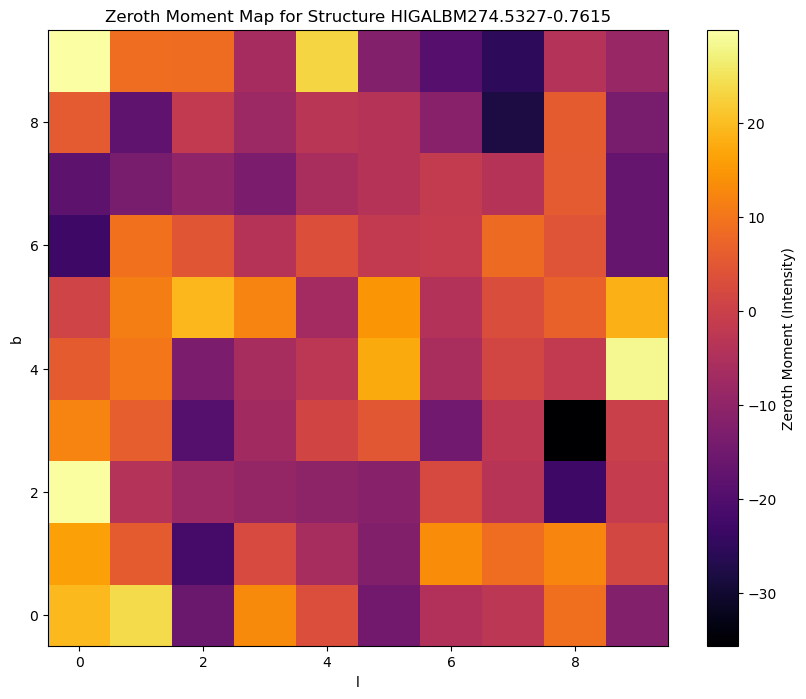

Saved zeroth moment map for structure HIGALBM277.7769-0.9359


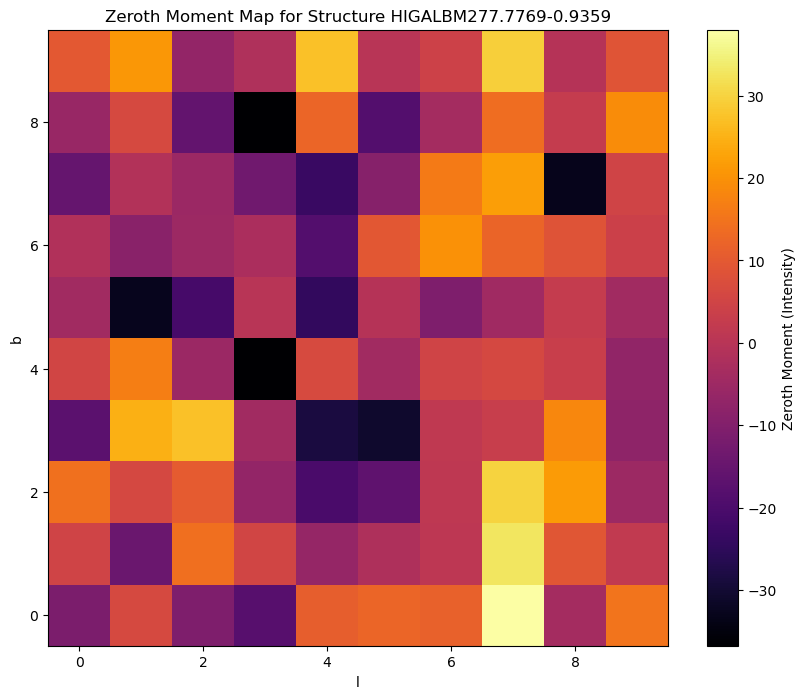

Saved zeroth moment map for structure HIGALBM279.5167-0.1544


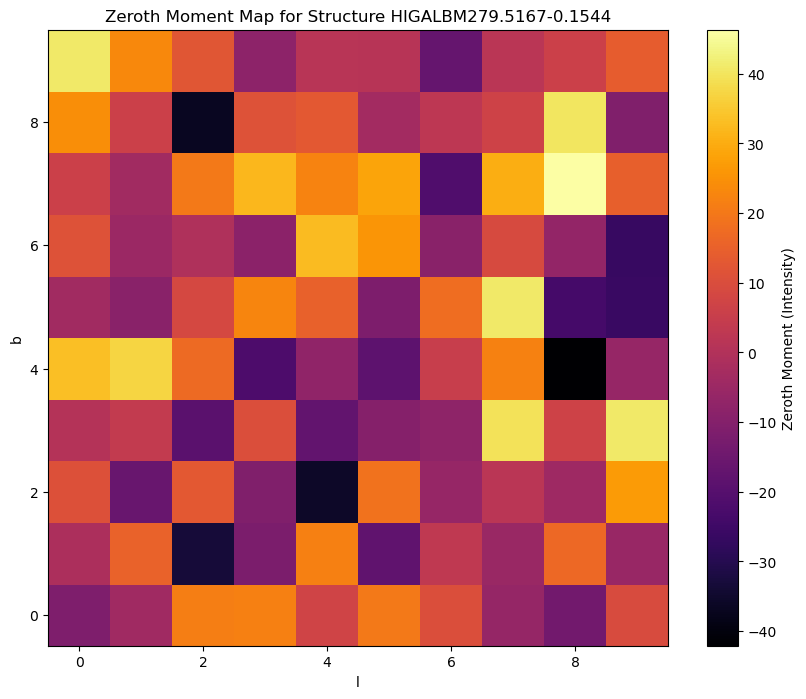

In [133]:
# Running the code

fits_file='/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/G270-280-12CO_giantcube_fullres.fits'
catalog_file='/Users/kyriakos.trakakis/Downloads/Mopra_250_260/MopraHigal_odd_sample_270.csv'
output_dir='/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/Moments/Odd_sample/Notebook_generated'
if __name__ == "__main__":
# Example usage
    compute_zeroth_moment_galactic(
    fits_file,
    catalog_file,
    output_dir,
    )

# Testing and debugging

In [8]:
catalog_file='/Users/kyriakos.trakakis/Downloads/Mopra_250_260/MopraHigal_odd_sample_250.csv'
fits_file='/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/G250-260-12CO_giantcube_fullres.fits'
catalog_data = pd.read_csv(catalog_file)
with fits.open(fits_file) as hdul:
    data = hdul[0].data
    header = hdul[0].header

In [9]:
wcs=WCS(header)
wcs

WCS Keywords

Number of WCS axes: 3
CTYPE : 'GLON-CAR'  'GLAT-CAR'  'VOPT'  
CRVAL : 350.5  0.0  0.0  
CRPIX : -10852.75  132.25  6148.0  
PC1_1 PC1_2 PC1_3  : 1.0  0.0  0.0  
PC2_1 PC2_2 PC2_3  : 0.0  1.0  0.0  
PC3_1 PC3_2 PC3_3  : 0.0  0.0  1.0  
CDELT : -0.00833333333334  0.00833333333334  100.0  
NAXIS : 1213  263  11139

In [11]:
print(wcs.pixel_n_dim)
print(wcs.array_shape) # Velocity, latitude, longitude
print(wcs.pixel_shape) # Longitude, latitude, velocity
print(wcs.world_axis_physical_types )
print(wcs.wcs.ctype)

3
(11139, 263, 1213)
(1213, 263, 11139)
['pos.galactic.lon', 'pos.galactic.lat', 'spect.dopplerVeloc.opt']
['GLON-CAR', 'GLAT-CAR', 'VOPT']


In [12]:
catalog_data[:4]

,HiGAL_id,gal_long,gal_lat,vlsr_2,dvlsr
0,HIGALBM253.9002-0.1621,253.900208,-0.16213,-91.8,0.4
1,HIGALBM254.7480-0.7909,254.748000,-0.79090,-82.5,0.4
2,HIGALBM258.1362-0.3913,258.136200,-0.39130,-45.4,0.4
3,HIGALBM250.6727-0.8238,250.672700,-0.82380,166.4,0.4


In [43]:
sec=catalog_data.iloc[2]
source_name = sec['HiGAL_id']  # Assuming the column for source names is 'Name'
l = sec['gal_long']           # Galactic Longitude
b = sec['gal_lat']           # Galactic Latitude
v_center = sec['vlsr_2']  # Central velocity
stddev = sec['dvlsr']

In [14]:
velocity_padding = 10
spatial_padding = 5 

In [15]:
l_low=header['CRVAL1']+(header['NAXIS1']-header['CRPIX1'])*header['CDELT1']
l_high=header['CRVAL1']+(1-header['CRPIX1'])*header['CDELT1']

b_high=header['CRVAL2']+(header['NAXIS2']-header['CRPIX2'])*header['CDELT2']
b_low=header['CRVAL2']+(1-header['CRPIX2'])*header['CDELT2']

v_high=header['CRVAL3']+(header['NAXIS3']-header['CRPIX3'])*header['CDELT3']/1000
v_low=header['CRVAL3']+(1-header['CRPIX3'])*header['CDELT3']/1000

In [16]:
print(l_low,l_high)
print(b_low,b_high)
print(v_low,v_high)

249.95208333325292 260.05208333326095
-1.093750000000875 1.0895833333342049
-614.7 499.1


In [30]:
x_pixel = (l - l_low) / np.abs(header['CDELT1'])  # CRVAL1 and CDELT1 correspond to longitude
y_pixel = (b - b_low) / header['CDELT2']  # CRVAL2 and CDELT2 correspond to latitude
v_pixel = (v_center - v_low) / header['CDELT3']*1000  # CRVAL3 is central velocity, CDELT3 is velocity step

x_min, x_max = max(int(x_pixel - spatial_padding), 0), min(int(x_pixel + spatial_padding), data.shape[2] - 1)
y_min, y_max = max(int(y_pixel - spatial_padding), 0), min(int(y_pixel + spatial_padding), data.shape[1] - 1)
v_min, v_max = max(int(v_pixel - velocity_padding), 0), min(int(v_pixel + velocity_padding), data.shape[0] - 1)

In [45]:
print(x_pixel,x_min,x_max)
print(y_pixel,y_min,y_max)
print(v_pixel,v_min,v_max)

982.0940000088614 977 987
84.29400000003758 79 89
5693.000000000001 5683 5703


In [44]:
source_name

'HIGALBM258.1362-0.3913'

In [46]:
data[5103, 127, 531]

-1.3769125

In [104]:
print(wcs.wcs.ctype)

['GLON-CAR', 'GLAT-CAR', 'VOPT']


In [125]:
print(x_pixel,x_min,x_max)
print(y_pixel,y_min,y_max)
print(v_pixel,v_min,v_max)

982.0940000088614 977 987
84.29400000003758 79 89
5693.0 5683 5703
